In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 110,
    'figure.autolayout': True
})
sns.set_palette('tab10')
print('Libraries imported successfully!')

Libraries imported successfully!


In [2]:
df = pd.read_csv('harsh_final_cicids.csv')
print(f'Dataset Loaded Successfully! Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

Dataset Loaded Successfully! Shape: 20,000 rows × 53 columns


In [3]:
df.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack Type
0,443,35160,2,6,6,0,3.0,4.242641,46,0,...,226,1,20,0.0,0,0,0.0,0,0,Normal Traffic
1,443,169,2,12,6,6,6.0,0.000000,0,0,...,-1,1,20,0.0,0,0,0.0,0,0,Normal Traffic
2,53,23157,1,52,52,52,52.0,0.000000,68,68,...,-1,0,20,0.0,0,0,0.0,0,0,Normal Traffic
3,53,30149,1,41,41,41,41.0,0.000000,122,122,...,-1,0,20,0.0,0,0,0.0,0,0,Normal Traffic
4,53285,42,1,6,6,6,6.0,0.000000,6,6,...,256,0,20,0.0,0,0,0.0,0,0,Normal Traffic


In [4]:
df.tail(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack Type
19995,53,24973,2,68,34,34,34.0,0.0,86,86,...,-1,1,20,0.0,0,0,0.0,0,0,Normal Traffic
19996,53,657,1,86,86,86,86.0,0.0,168,168,...,-1,0,20,0.0,0,0,0.0,0,0,Normal Traffic
19997,53,140,2,88,44,44,44.0,0.0,60,60,...,-1,1,32,0.0,0,0,0.0,0,0,Normal Traffic
19998,53,31144,2,64,32,32,32.0,0.0,48,48,...,-1,1,20,0.0,0,0,0.0,0,0,Normal Traffic
19999,80,3003035,3,0,0,0,0.0,0.0,0,0,...,-1,0,40,0.0,0,0,0.0,0,0,DoS


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 53 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Destination Port             20000 non-null  int64  
 1   Flow Duration                20000 non-null  int64  
 2   Total Fwd Packets            20000 non-null  int64  
 3   Total Length of Fwd Packets  20000 non-null  int64  
 4   Fwd Packet Length Max        20000 non-null  int64  
 5   Fwd Packet Length Min        20000 non-null  int64  
 6   Fwd Packet Length Mean       20000 non-null  float64
 7   Fwd Packet Length Std        20000 non-null  float64
 8   Bwd Packet Length Max        20000 non-null  int64  
 9   Bwd Packet Length Min        20000 non-null  int64  
 10  Bwd Packet Length Mean       20000 non-null  float64
 11  Bwd Packet Length Std        20000 non-null  float64
 12  Flow Bytes/s                 20000 non-null  float64
 13  Flow Packets/s             

In [6]:
missing_count = df.isnull().sum().sum()
dup_count = df.duplicated().sum()
print(f'Total Missing Values: {missing_count}')
print(f'Total Duplicate Rows: {dup_count}')
print('Numeric Columns Count:', len(df.select_dtypes(include=[np.number]).columns))

Total Missing Values: 0
Total Duplicate Rows: 0
Numeric Columns Count: 52


In [7]:
key_cols = ['Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 
            'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean', 'Average Packet Size', 'Idle Mean']
df[key_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Flow Duration,20000.0,1.447385e+07,3.420477e+07,1.00000,197.000000,52802.000000,4.066138e+06,1.199989e+08
Total Fwd Packets,20000.0,6.817650e+00,3.323895e+01,1.00000,2.000000,2.000000,4.000000e+00,1.301000e+03
Total Length of Fwd Packets,20000.0,5.080140e+02,3.080075e+03,0.00000,12.000000,58.000000,1.440000e+02,2.323490e+05
Flow Bytes/s,20000.0,1.733049e+06,3.295693e+07,0.00000,35.584635,4150.401855,1.264478e+05,2.070000e+09
Flow Packets/s,20000.0,4.150303e+04,1.887792e+05,0.02837,2.082761,65.911251,1.809955e+04,3.000000e+06
Packet Length Mean,20000.0,1.269909e+02,2.620172e+02,0.00000,6.000000,50.828571,9.565952e+01,1.661000e+03
Average Packet Size,20000.0,1.444002e+02,2.888920e+02,0.00000,9.000000,66.000000,1.245000e+02,2.068000e+03
Idle Mean,20000.0,5.199796e+06,1.724807e+07,0.00000,0.000000,0.000000,0.000000e+00,1.190000e+08


In [8]:
attack_counts = df['Attack Type'].value_counts()
attack_shares = df['Attack Type'].value_counts(normalize=True) * 100
summary_attacks = pd.DataFrame({
    'Count': attack_counts,
    'Percentage (%)': attack_shares.round(2)
})
print(summary_attacks)

                Count  Percentage (%)
Attack Type                          
Normal Traffic  15000            75.0
DoS              1800             9.0
DDoS             1300             6.5
Port Scanning    1000             5.0
Brute Force       400             2.0
Web Attacks       300             1.5
Bots              200             1.0


In [9]:
df['Label'] = np.where(df['Attack Type'] == 'Normal Traffic', 'Normal', 'Attack')
label_counts = df['Label'].value_counts()
print('Binary Label Distribution:')
print(pd.DataFrame({'Count': label_counts, 'Share (%)': (df['Label'].value_counts(normalize=True)*100).round(2)}))

Binary Label Distribution:
        Count  Share (%)
Label                   
Normal  15000       75.0
Attack   5000       25.0


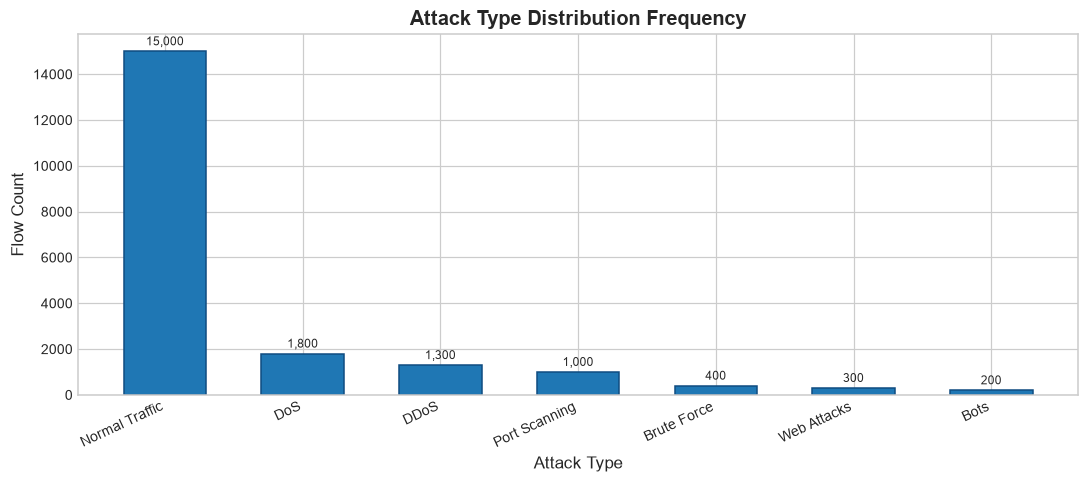

In [10]:
plt.figure(figsize=(10, 4.5))
bars = plt.bar(attack_counts.index, attack_counts.values, color='#1f77b4', edgecolor='#0f4c81', width=0.6)
plt.title('Attack Type Distribution Frequency', fontweight='bold')
plt.xlabel('Attack Type')
plt.ylabel('Flow Count')
plt.xticks(rotation=25, ha='right')
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 150, f'{int(y):,}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

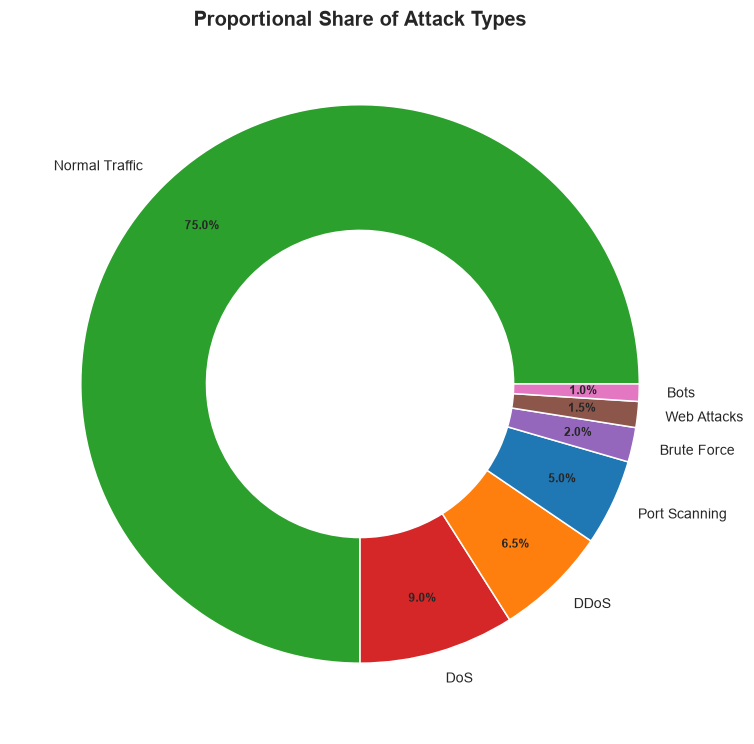

In [11]:
plt.figure(figsize=(7, 7))
colors = ['#2ca02c', '#d62728', '#ff7f0e', '#1f77b4', '#9467bd', '#8c564b', '#e377c2']
wedges, texts, autotexts = plt.pie(
    attack_counts.values,
    labels=attack_counts.index,
    autopct='%1.1f%%',
    pctdistance=0.8,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='white')
)
plt.setp(autotexts, size=8, weight='bold')
plt.title('Proportional Share of Attack Types', fontweight='bold')
plt.show()

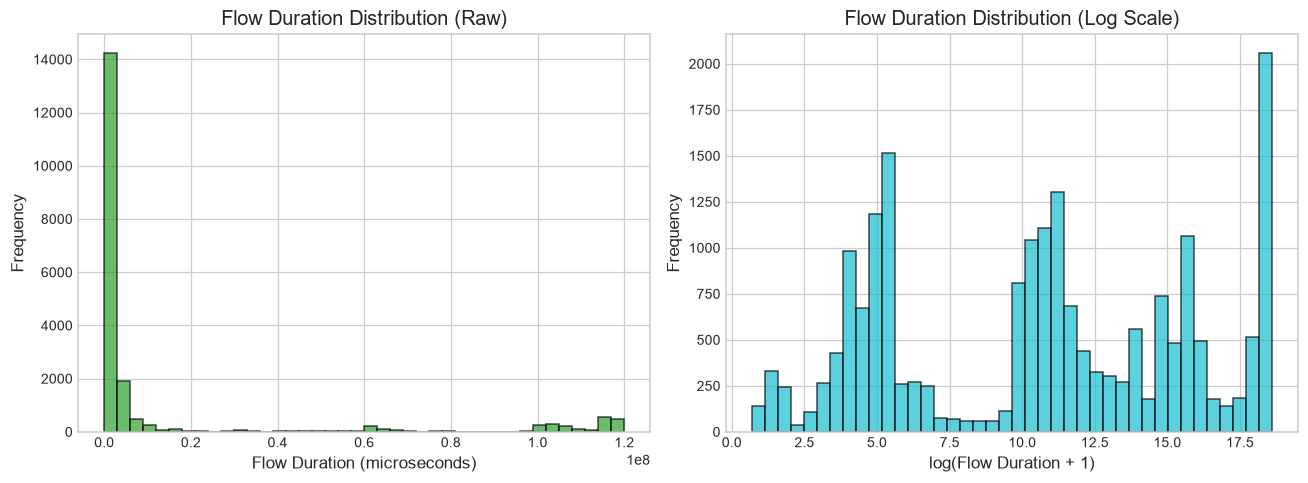

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.hist(df['Flow Duration'], bins=40, color='#2ca02c', edgecolor='black', alpha=0.7)
ax1.set_title('Flow Duration Distribution (Raw)')
ax1.set_xlabel('Flow Duration (microseconds)')
ax1.set_ylabel('Frequency')
ax2.hist(np.log1p(df['Flow Duration']), bins=40, color='#17becf', edgecolor='black', alpha=0.7)
ax2.set_title('Flow Duration Distribution (Log Scale)')
ax2.set_xlabel('log(Flow Duration + 1)')
ax2.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

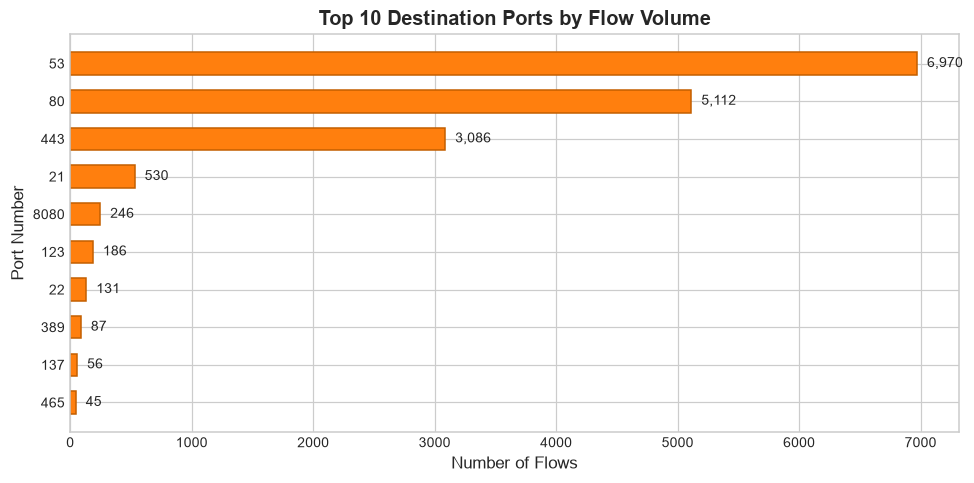

In [13]:
top_ports = df['Destination Port'].value_counts().head(10)
plt.figure(figsize=(9, 4.5))
plt.barh(top_ports.index.astype(str), top_ports.values, color='#ff7f0e', edgecolor='#c45f00', height=0.6)
plt.gca().invert_yaxis()
plt.title('Top 10 Destination Ports by Flow Volume', fontweight='bold')
plt.xlabel('Number of Flows')
plt.ylabel('Port Number')
for i, v in enumerate(top_ports.values):
    plt.text(v + 50, i, f' {v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

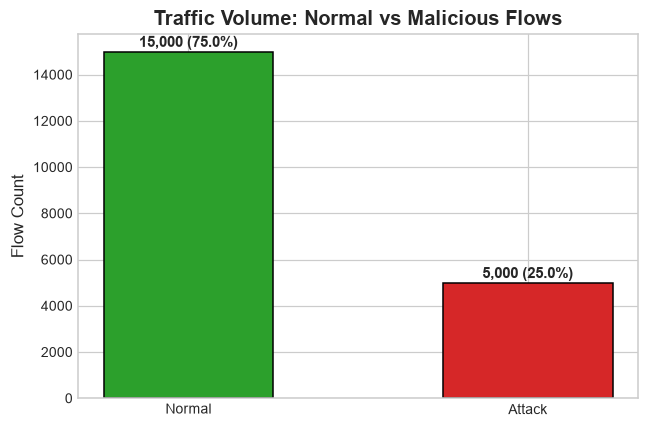

In [14]:
plt.figure(figsize=(6, 4))
plt.bar(label_counts.index, label_counts.values, color=['#2ca02c', '#d62728'], width=0.5, edgecolor='black')
plt.title('Traffic Volume: Normal vs Malicious Flows', fontweight='bold')
plt.ylabel('Flow Count')
for i, v in enumerate(label_counts.values):
    plt.text(i, v + 200, f'{v:,} ({(v/len(df)*100):.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

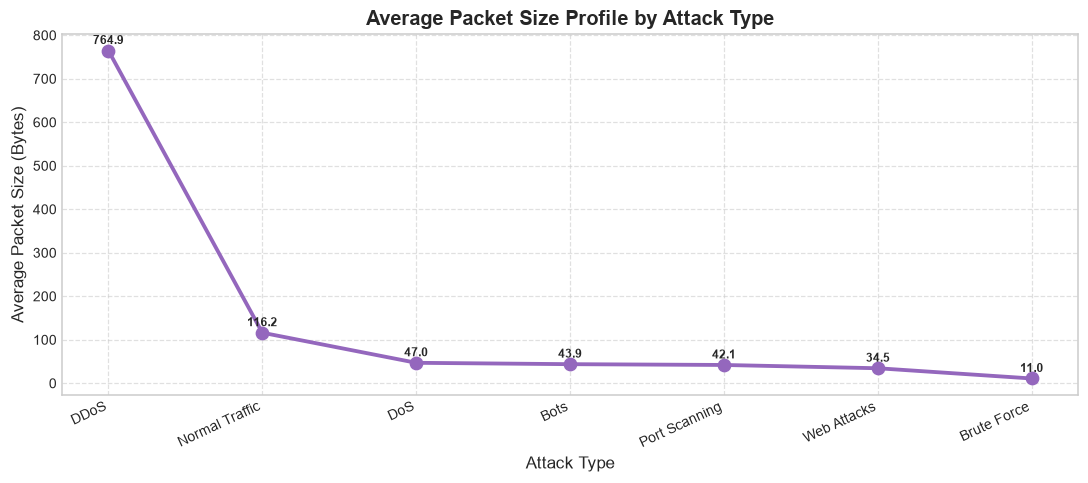

In [15]:
avg_pkt_by_attack = df.groupby('Attack Type')['Average Packet Size'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 4.5))
plt.plot(avg_pkt_by_attack.index, avg_pkt_by_attack.values, marker='o', linewidth=2.5, markersize=8, color='#9467bd')
plt.title('Average Packet Size Profile by Attack Type', fontweight='bold')
plt.xlabel('Attack Type')
plt.ylabel('Average Packet Size (Bytes)')
plt.xticks(rotation=25, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
for i, v in enumerate(avg_pkt_by_attack.values):
    plt.text(i, v + 15, f'{v:.1f}', ha='center', fontsize=8, weight='bold')
plt.tight_layout()
plt.show()

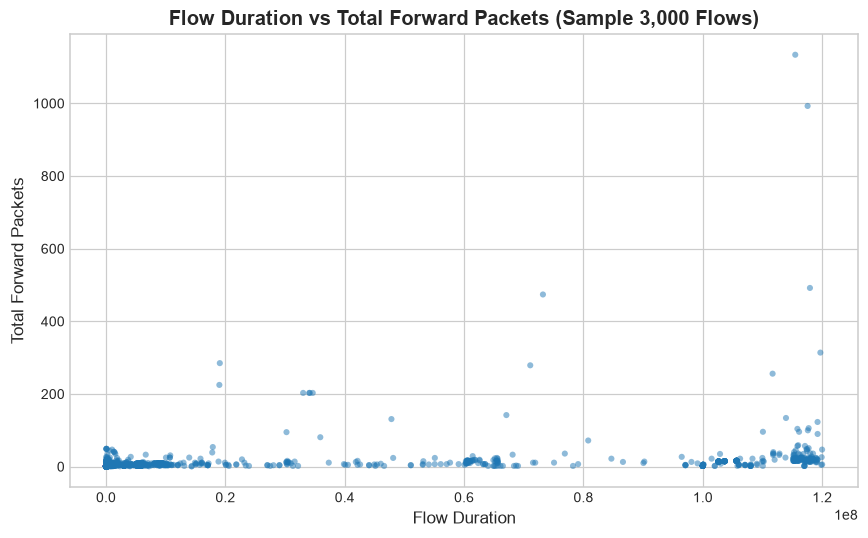

In [16]:
plt.figure(figsize=(8, 5))
sample_scatter = df.sample(min(3000, len(df)), random_state=42)
plt.scatter(sample_scatter['Flow Duration'], sample_scatter['Total Fwd Packets'], alpha=0.5, c='#1f77b4', s=16, edgecolors='none')
plt.title('Flow Duration vs Total Forward Packets (Sample 3,000 Flows)', fontweight='bold')
plt.xlabel('Flow Duration')
plt.ylabel('Total Forward Packets')
plt.tight_layout()
plt.show()

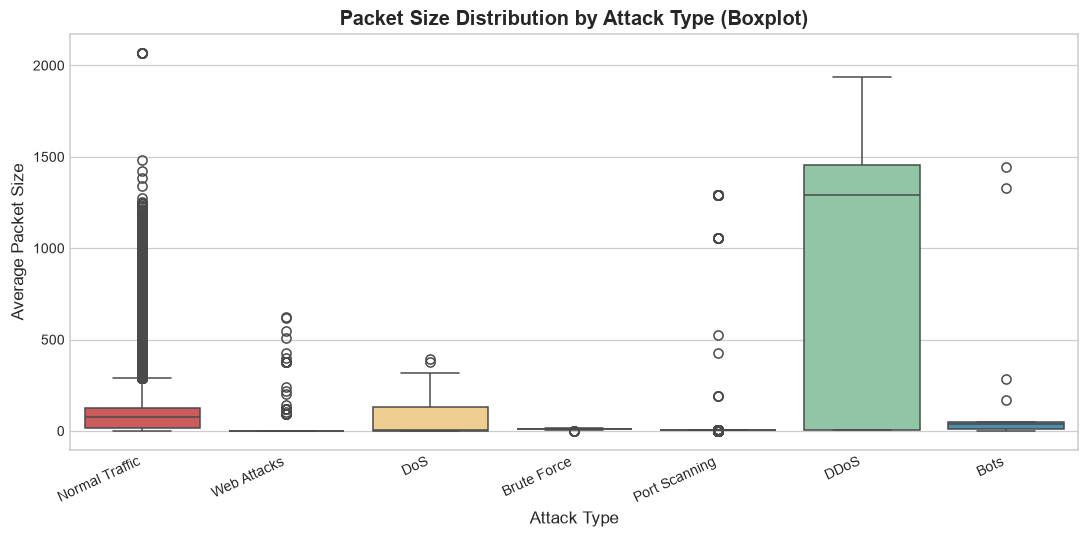

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Attack Type', y='Average Packet Size', data=df, palette='Spectral', hue='Attack Type', legend=False)
plt.title('Packet Size Distribution by Attack Type (Boxplot)', fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

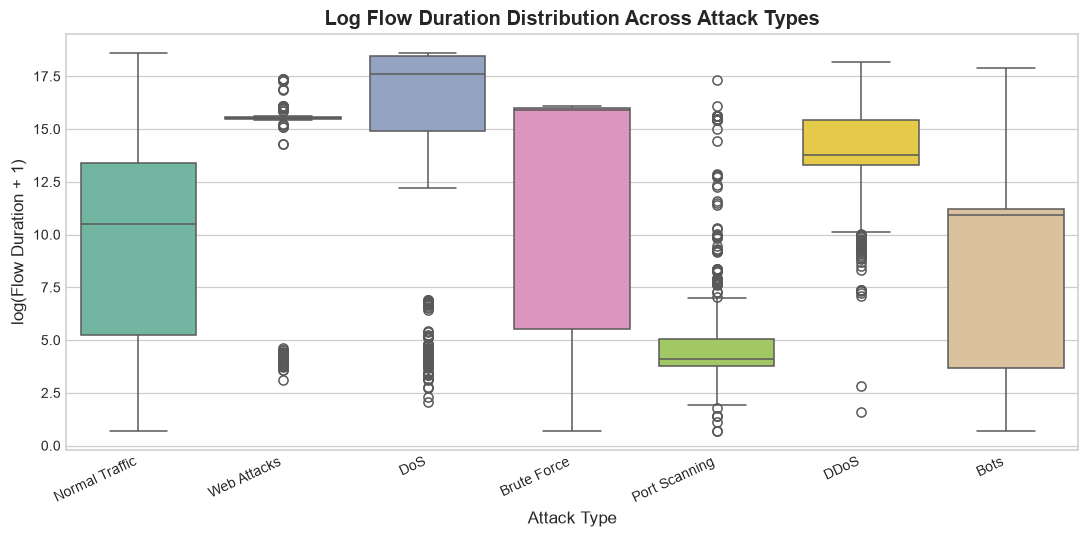

In [18]:
plt.figure(figsize=(10, 5))
df['Log_Flow_Duration'] = np.log1p(df['Flow Duration'])
sns.boxplot(x='Attack Type', y='Log_Flow_Duration', data=df, palette='Set2', hue='Attack Type', legend=False)
plt.title('Log Flow Duration Distribution Across Attack Types', fontweight='bold')
plt.ylabel('log(Flow Duration + 1)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

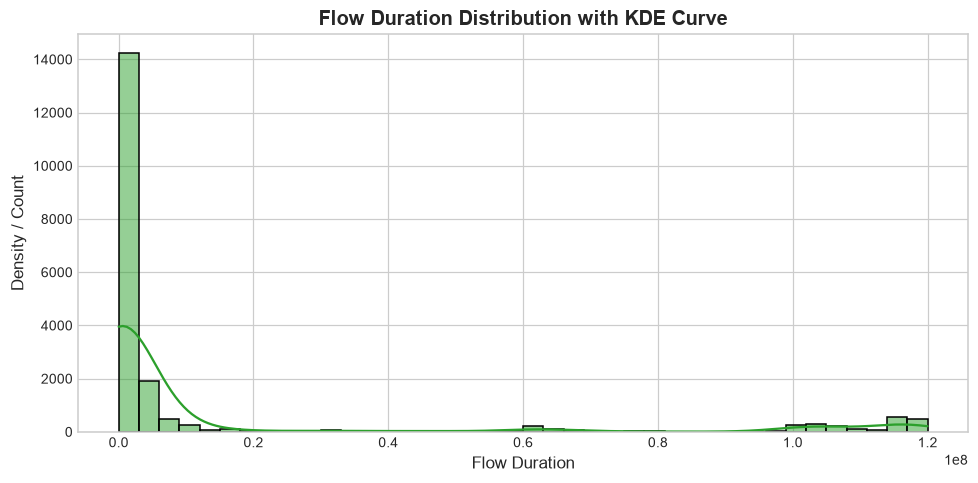

In [19]:
plt.figure(figsize=(9, 4.5))
sns.histplot(df['Flow Duration'], bins=40, kde=True, color='#2ca02c')
plt.title('Flow Duration Distribution with KDE Curve', fontweight='bold')
plt.xlabel('Flow Duration')
plt.ylabel('Density / Count')
plt.tight_layout()
plt.show()

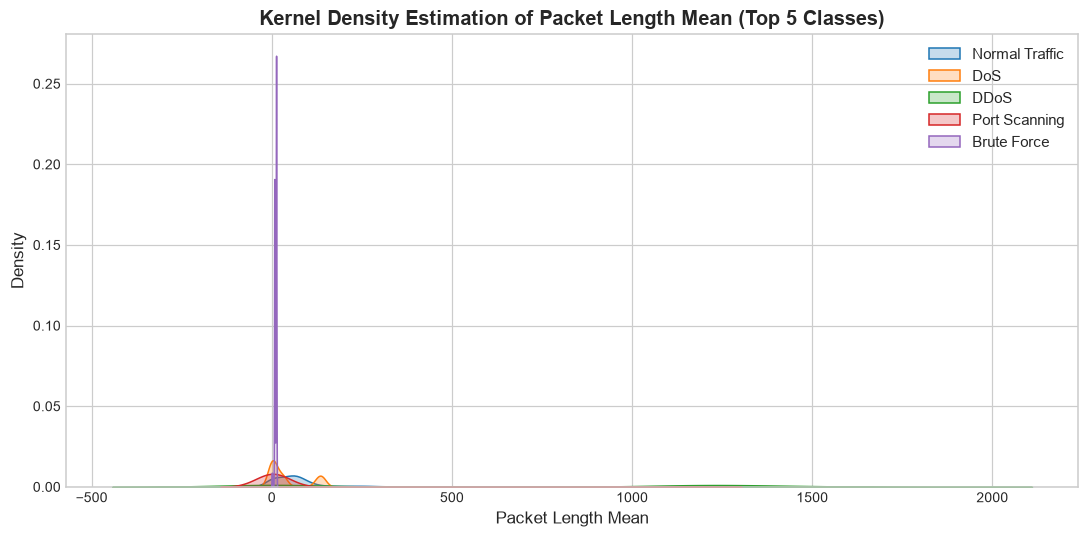

In [20]:
top_attacks = list(attack_counts.index[:5])
plt.figure(figsize=(10, 5))
for attack in top_attacks:
    subset = df[df['Attack Type'] == attack]
    sns.kdeplot(subset['Packet Length Mean'], label=attack, fill=True, alpha=0.25)
plt.title('Kernel Density Estimation of Packet Length Mean (Top 5 Classes)', fontweight='bold')
plt.xlabel('Packet Length Mean')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

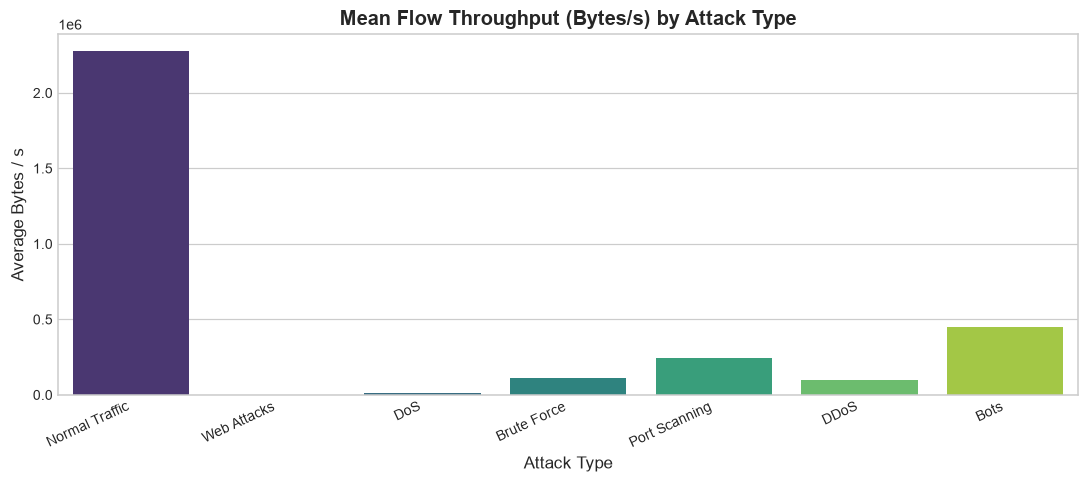

In [21]:
plt.figure(figsize=(10, 4.5))
sns.barplot(x='Attack Type', y='Flow Bytes/s', data=df, estimator=np.mean, errorbar=None, palette='viridis', hue='Attack Type', legend=False)
plt.title('Mean Flow Throughput (Bytes/s) by Attack Type', fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.ylabel('Average Bytes / s')
plt.tight_layout()
plt.show()

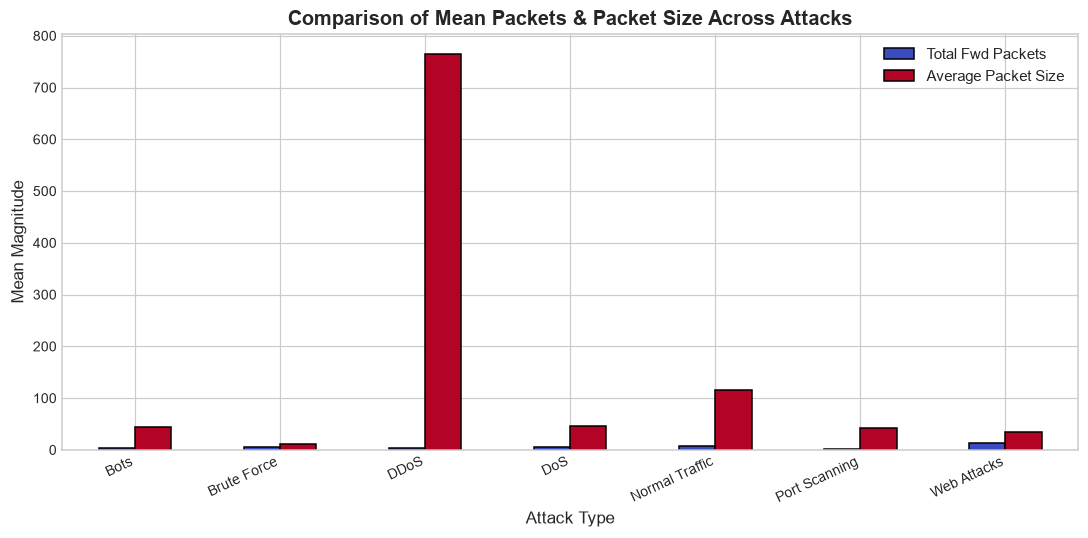

In [22]:
attack_grouped = df.groupby('Attack Type')[['Total Fwd Packets', 'Average Packet Size']].mean()
attack_grouped.plot(kind='bar', figsize=(10, 5), colormap='coolwarm', edgecolor='black')
plt.title('Comparison of Mean Packets & Packet Size Across Attacks', fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.ylabel('Mean Magnitude')
plt.tight_layout()
plt.show()

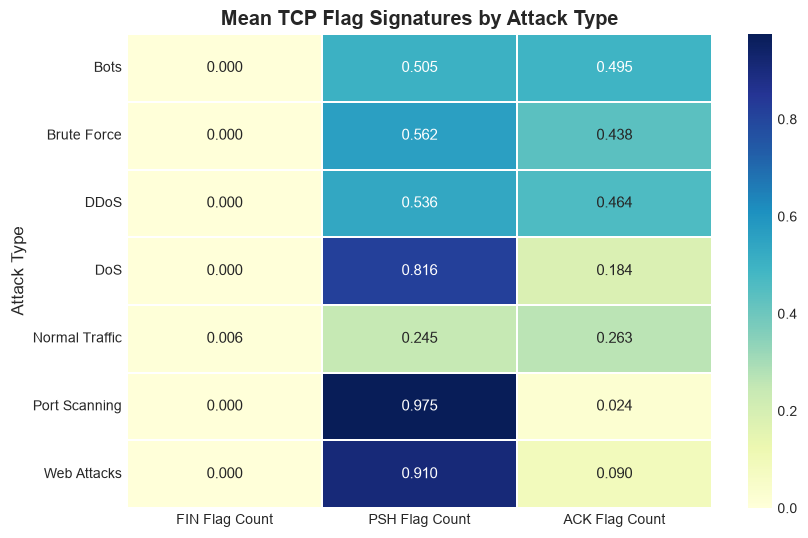

In [23]:
flag_cols = ['FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count']
flags_mean = df.groupby('Attack Type')[flag_cols].mean()
plt.figure(figsize=(8, 5))
sns.heatmap(flags_mean, annot=True, fmt='.3f', cmap='YlGnBu', linewidths=1)
plt.title('Mean TCP Flag Signatures by Attack Type', fontweight='bold')
plt.ylabel('Attack Type')
plt.tight_layout()
plt.show()

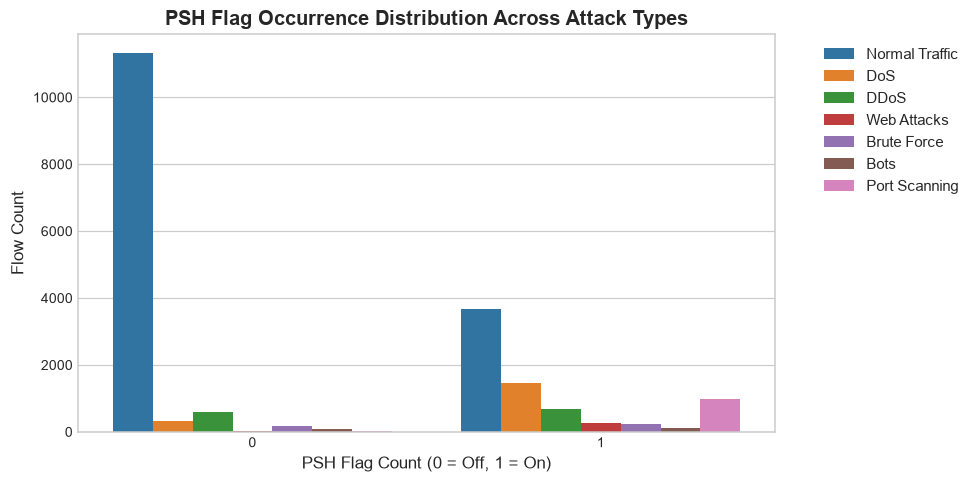

In [24]:
plt.figure(figsize=(9, 4.5))
sns.countplot(x='PSH Flag Count', hue='Attack Type', data=df, palette='tab10')
plt.title('PSH Flag Occurrence Distribution Across Attack Types', fontweight='bold')
plt.xlabel('PSH Flag Count (0 = Off, 1 = On)')
plt.ylabel('Flow Count')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

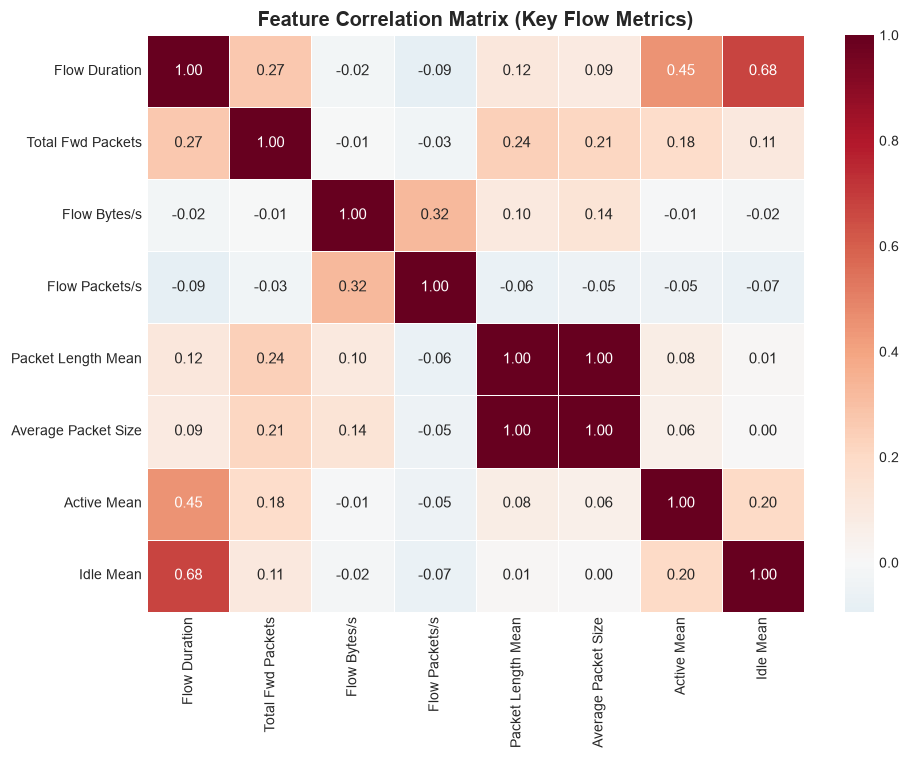

In [25]:
corr_features = [
    'Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Flow Packets/s',
    'Packet Length Mean', 'Average Packet Size', 'Active Mean', 'Idle Mean'
]
corr_matrix = df[corr_features].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix (Key Flow Metrics)', fontweight='bold')
plt.tight_layout()
plt.show()

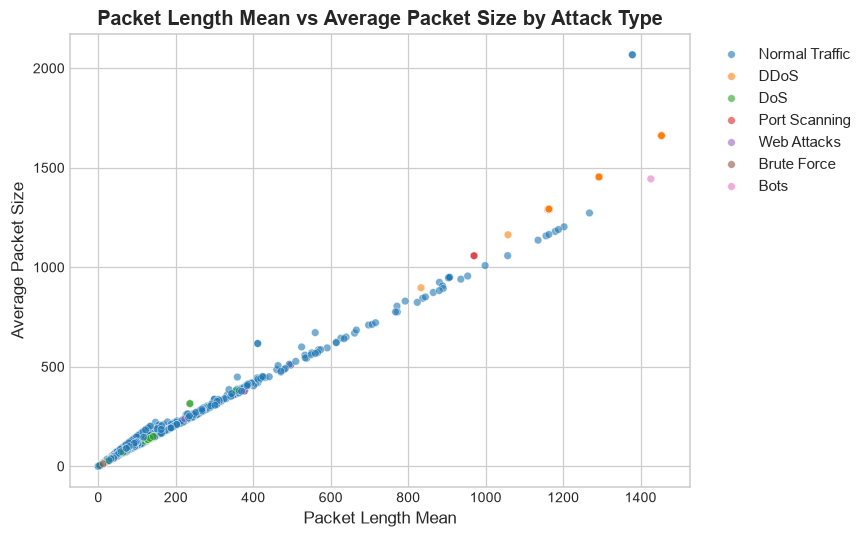

In [26]:
plt.figure(figsize=(8, 5))
sample_scatter = df.sample(min(2500, len(df)), random_state=42)
sns.scatterplot(
    data=sample_scatter,
    x='Packet Length Mean',
    y='Average Packet Size',
    hue='Attack Type',
    palette='tab10',
    alpha=0.6,
    s=25
)
plt.title('Packet Length Mean vs Average Packet Size by Attack Type', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

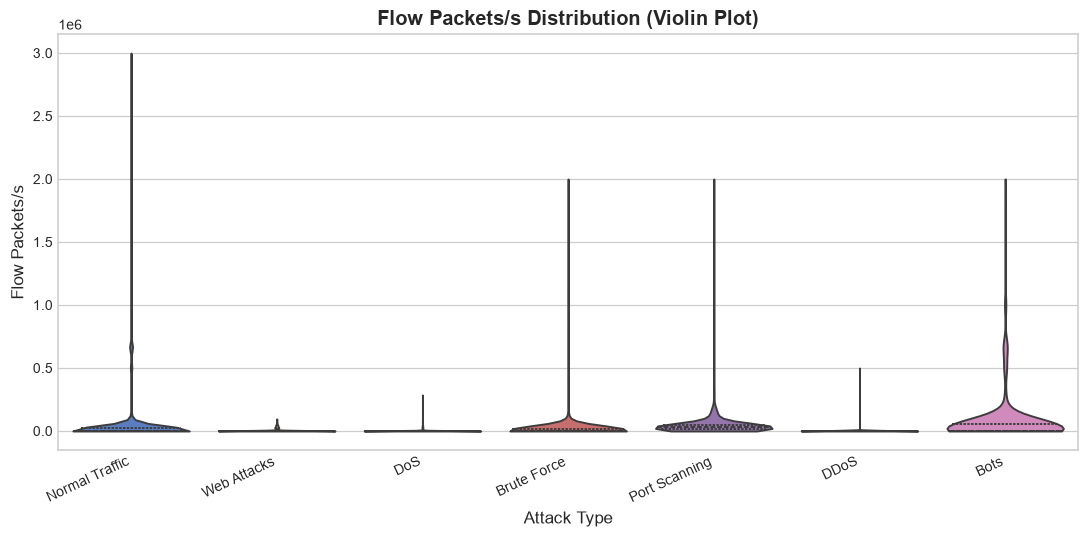

In [27]:
plt.figure(figsize=(10, 5))
sns.violinplot(
    x='Attack Type',
    y='Flow Packets/s',
    data=df,
    palette='muted',
    hue='Attack Type',
    legend=False,
    inner='quartile',
    cut=0
)
plt.title('Flow Packets/s Distribution (Violin Plot)', fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

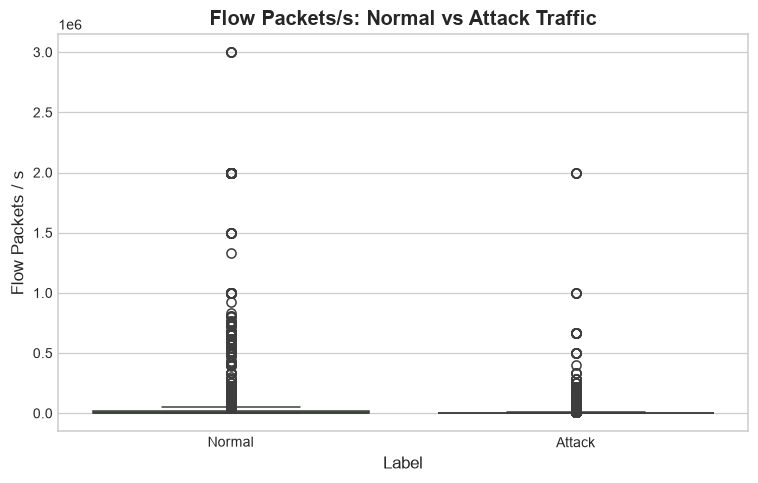

In [28]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='Label', y='Flow Packets/s', data=df, palette=['#2ca02c', '#d62728'], hue='Label', legend=False)
plt.title('Flow Packets/s: Normal vs Attack Traffic', fontweight='bold')
plt.ylabel('Flow Packets / s')
plt.tight_layout()
plt.show()

Mean Metrics by Label:
        Flow Duration  Total Fwd Packets  Average Packet Size     Idle Mean
Label                                                                      
Attack   2.063416e+07           4.806800           228.928632  1.097229e+07
Normal   1.242041e+07           7.487933           116.223999  3.275631e+06


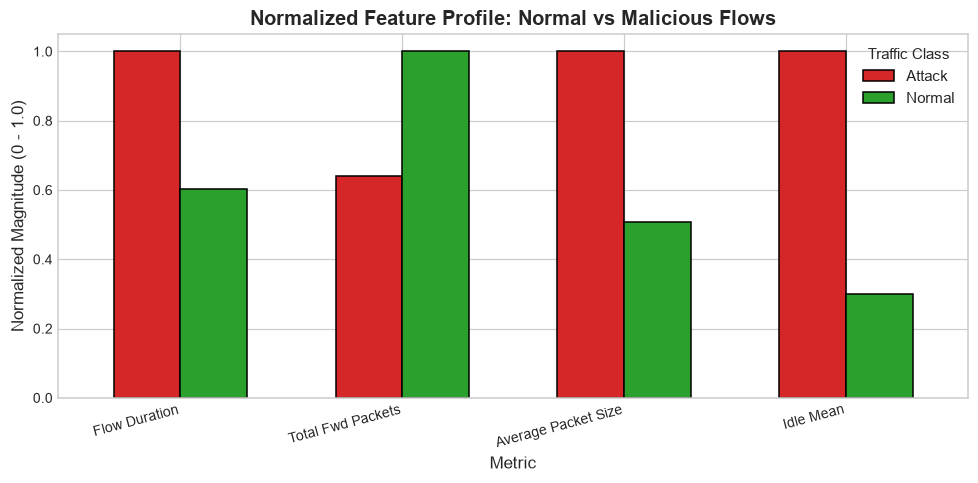

In [29]:
label_summary = df.groupby('Label')[['Flow Duration', 'Total Fwd Packets', 'Average Packet Size', 'Idle Mean']].mean()
print('Mean Metrics by Label:')
print(label_summary)
scaled_summary = label_summary / label_summary.max()
scaled_summary.T.plot(kind='bar', figsize=(9, 4.5), color=['#d62728', '#2ca02c'], edgecolor='black', width=0.6)
plt.title('Normalized Feature Profile: Normal vs Malicious Flows', fontweight='bold')
plt.xlabel('Metric')
plt.ylabel('Normalized Magnitude (0 - 1.0)')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Traffic Class')
plt.tight_layout()
plt.show()

In [30]:
duration_stats = df.groupby('Attack Type')['Flow Duration'].agg(['count', 'min', 'max', 'mean', 'median', 'std'])
print('--- Flow Duration Statistics by Attack Type ---')
print(duration_stats.round(2))

--- Flow Duration Statistics by Attack Type ---


                count  min        max         mean      median          std
Attack Type                                                                
Bots              200    1   60202640    343143.30     56393.5   4254229.12
Brute Force       400    1    9785070   4938050.58   8169944.0   4391719.53
DDoS             1300    4   80034360   3377432.21    974730.0   6569535.74
DoS              1800    7  119046064  52569239.78  44074059.0  49639406.15
Normal Traffic  15000    1  119998926  12420413.00     36907.5  32402374.06
Port Scanning    1000    1   34167189    142394.94        60.0   1331617.66
Web Attacks       300   21   35451960   6564147.03   5541765.5   6451649.02


In [31]:
pkt_stats = df.groupby('Attack Type')['Average Packet Size'].agg(['count', 'min', 'max', 'mean', 'median', 'std'])
print('--- Average Packet Size Statistics by Attack Type ---')
print(pkt_stats.round(2))

--- Average Packet Size Statistics by Attack Type ---
                count  min      max    mean   median     std
Attack Type                                                 
Bots              200  0.0  1444.18   43.91    35.61  138.47
Brute Force       400  0.0    14.00   10.97    12.04    2.13
DDoS             1300  7.0  1937.83  764.89  1291.89  706.37
DoS              1800  0.0   393.84   47.04     8.00   61.00
Normal Traffic  15000  0.0  2068.00  116.22    76.25  165.51
Port Scanning    1000  0.0  1290.33   42.07     5.00  208.23
Web Attacks       300  0.0   624.47   34.53     0.00  108.34


In [32]:
top_port_list = df['Destination Port'].value_counts().head(6).index.tolist()
port_pivot = df[df['Destination Port'].isin(top_port_list)].pivot_table(
    index='Attack Type',
    columns='Destination Port',
    values='Flow Duration',
    aggfunc='count',
    fill_value=0
)
print('--- Port Targeting Pivot Table (Flow Counts) ---')
print(port_pivot)

--- Port Targeting Pivot Table (Flow Counts) ---
Destination Port  21    53    80    123   443   8080
Attack Type                                         
Bots                 0     0     0     0     0   104
Brute Force        399     0     1     0     0     0
DDoS                 0     0  1300     0     0     0
DoS                  0     0  1800     0     0     0
Normal Traffic      66  6970  1592   186  3023   142
Port Scanning       65     0   119     0    63     0
Web Attacks          0     0   300     0     0     0


In [33]:
print('Complete CICIDS 2017 Traffic Analysis Executed Successfully!')

Complete CICIDS 2017 Traffic Analysis Executed Successfully!
